> **Public copy.** The outputs below are from the original run on the private database. After that run, product, vendor and system names and release numbers in the code, text and tables were replaced with the public codes used everywhere in this repository (Vendor A to E; releases such as 1.51 and "Vendor C 3.0"), so every number is exactly as computed. The database itself is not published; the anonymised data files are in `data/`.


# 10 The model ladder (step 5)

**Goal:** predict, **before a release starts**, which components will be hotspots (label D from notebook 08), and find out how much each model adds over simple rules.

**The ladder (the course mentor's advice, plus one extra baseline):**
1. **"Always high"**: flags every row (the course mentor's baseline).
2. **Usual-rate rule**: flags a component when its usual rate (defects per 10 person-days in earlier releases) is already above its stream's hotspot line. This is what an experienced QA lead might do by hand.
3. **Logistic regression**: a weighted sum of the inputs.
4. **Decision tree**, depth 3 to 5: a few yes/no questions anyone can read.
5. **Random forest**: many trees voting together (the accuracy check).

All models use **balanced class weights** (step 4). No XGBoost: the data is too small.

**Decided on the training releases only** (three time-ordered checks; the 16 test releases stay untouched):
- recency half-life: 2 or 4 releases (Jagan: keep whichever predicts better);
- with or without 1.37 and Vendor C 3.0, whose effort is estimated (Jagan: try both);
- each model's settings.

**How the winner is picked (agreed with Jagan before running, 24 Nov 2026):** the model with the best average ranking score (PR-AUC) on the training checks wins. If two models are within 0.02, the easier one to explain wins: the decision tree first, then logistic regression, then the random forest. Then every model gets **one** honest score on the test releases, and all results are recorded.

| Measure | In plain words |
| --- | --- |
| PR-AUC | How well the model puts real hotspots at the top of its list (1 = perfect; guessing scores the share of hotspots) |
| Recall | Of the real hotspots, the share the model flagged |
| Precision | Of the rows the model flagged, the share that were real hotspots |
| MCC | One balanced score from -1 to 1 (0 = guessing), fair when hotspots are rare |
| Brier | How close the risk scores are to what happened (0 = perfect; models only) |
| Capture in top 20% | If QA tests the top 20% of rows first, the share of hotspots covered |

In [1]:
import sqlite3, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works whether you run from the project folder or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'scripts'))
CLEAN = ROOT / 'data' / 'private' / 'hindsight_clean.sqlite'  # our cleaned tables
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', None)     # show tree rules and component lists in full
warnings.filterwarnings('ignore', category=FutureWarning)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, matthews_corrcoef, recall_score, precision_score,
                             brier_score_loss)
from hs_features import FEATURES_NUM, FEATURES_CAT

with sqlite3.connect(CLEAN) as cc:
    fact = pd.read_sql('select * from fact_labelled', cc, parse_dates=['window_start', 'window_end'])
fact['effort_estimated'] = fact.effort_estimated.astype(bool)
train, test = fact[fact.split == 'train'], fact[fact.split == 'test']
print(f'train: {len(train)} rows, {int(train.high_risk.sum())} hotspots | test: {len(test)} rows, {int(test.high_risk.sum())} hotspots')

train: 380 rows, 96 hotspots | test: 161 rows, 24 hotspots


## 1. The setups, models and checks

In [2]:
SETUPS = {}
for hl in (2, 4):
    other = 'recent_rate_hl4' if hl == 2 else 'recent_rate_hl2'
    num = [f for f in FEATURES_NUM if f != other]
    for keep in (True, False):
        name = f'half-life {hl}, ' + ('with' if keep else 'without') + ' 1.37 and Vendor C 3.0'
        SETUPS[name] = {'num': num, 'keep_estimated': keep}

def pipeline(num, model, scale):
    prep = ColumnTransformer([
        ('num', Pipeline([('fill', SimpleImputer(strategy='median'))] + ([('scale', StandardScaler())] if scale else [])), num),
        ('cat', OneHotEncoder(handle_unknown='ignore'), FEATURES_CAT)])
    return Pipeline([('prep', prep), ('model', model)])

MODELS = {
    'Logistic regression': (lambda s: LogisticRegression(C=s, class_weight='balanced', max_iter=3000), True,
                            [0.03, 0.1, 0.3, 1.0]),
    'Decision tree': (lambda s: DecisionTreeClassifier(max_depth=s[0], min_samples_leaf=s[1], class_weight='balanced',
                                                       random_state=42), False,
                      [(d, leaf) for d in (3, 4, 5) for leaf in (5, 10, 20)]),
    'Random forest': (lambda s: RandomForestClassifier(n_estimators=300, max_depth=s[0], min_samples_leaf=s[1],
                                                       class_weight='balanced_subsample', random_state=42, n_jobs=-1), False,
                      [(d, leaf) for d in (3, 5, None) for leaf in (3, 5, 10)]),
}

order = train.groupby('release_key').window_start.min().sort_values()
n = len(order)
cuts = [int(n * q) for q in (0.55, 0.70, 0.85)] + [n]
folds = [(order.index[:cuts[i]], order.index[cuts[i]:cuts[i + 1]]) for i in range(3)]
print(len(SETUPS), 'setups x', sum(len(g) for _, _, g in MODELS.values()), 'model settings x 3 checks')

4 setups x 22 model settings x 3 checks


## 2. Training checks: every setup, model and setting

Each check learns from the older training releases and is scored on the next ones. Rows of 1.37 and Vendor C 3.0 are dropped from the learning part in the "without" setups.

In [3]:
def rows_to_learn(df, keep_estimated):
    return df if keep_estimated else df[~df.effort_estimated]

cv_rows = []
for setup, cfg in SETUPS.items():
    cols = cfg['num'] + FEATURES_CAT
    for model_name, (make, scale, grid) in MODELS.items():
        for setting in grid:
            scores = []
            for fit_rel, check_rel in folds:
                a = rows_to_learn(train[train.release_key.isin(fit_rel)], cfg['keep_estimated'])
                b = train[train.release_key.isin(check_rel)]
                m = pipeline(cfg['num'], make(setting), scale).fit(a[cols], a.high_risk)
                scores.append(average_precision_score(b.high_risk, m.predict_proba(b[cols])[:, 1]))
            cv_rows.append({'setup': setup, 'model': model_name, 'setting': str(setting),
                            'PR-AUC': np.mean(scores), 'lowest check': min(scores), 'highest check': max(scores)})
cv = pd.DataFrame(cv_rows)
best_per = cv.sort_values('PR-AUC', ascending=False).drop_duplicates(['setup', 'model'])
best_per.pivot(index='setup', columns='model', values='PR-AUC').round(3)

model,Decision tree,Logistic regression,Random forest
setup,,,
"half-life 2, with 1.37 and Vendor C 3.0",0.718,0.747,0.836
"half-life 2, without 1.37 and Vendor C 3.0",0.665,0.749,0.837
"half-life 4, with 1.37 and Vendor C 3.0",0.713,0.738,0.834
"half-life 4, without 1.37 and Vendor C 3.0",0.646,0.749,0.838


## 3. Choosing the setup, then the winning model (the agreed rule)

**Setup:** the one with the best average PR-AUC across the three models (one half-life and one row set for every model). **Model:** the best PR-AUC in that setup; within 0.02 of the best, the easier one to explain wins (tree, then logistic regression, then random forest).

In [4]:
setup_score = best_per.groupby('setup')['PR-AUC'].mean().sort_values(ascending=False)
SETUP = setup_score.index[0]
print('Setup scores (average of the three models):')
print(setup_score.round(3).to_string(), end='\n\n')
print('Chosen setup:', SETUP)

chosen = best_per[best_per.setup == SETUP].set_index('model')
CHOSEN_SETTING = {m: eval(chosen.loc[m, 'setting']) for m in MODELS}
top = chosen['PR-AUC'].max()
FINAL = next(m for m in ['Decision tree', 'Logistic regression', 'Random forest'] if chosen.loc[m, 'PR-AUC'] >= top - 0.02)
print(chosen[['setting', 'PR-AUC', 'lowest check', 'highest check']].round(3), end='\n\n')
print(f'Winner by the agreed rule: {FINAL} (training-check PR-AUC {chosen.loc[FINAL, "PR-AUC"]:.3f}; best {top:.3f})')

Setup scores (average of the three models):
setup
half-life 2, with 1.37 and Vendor C 3.0       0.767
half-life 4, with 1.37 and Vendor C 3.0       0.762
half-life 2, without 1.37 and Vendor C 3.0    0.750
half-life 4, without 1.37 and Vendor C 3.0    0.744

Chosen setup: half-life 2, with 1.37 and Vendor C 3.0
                       setting  PR-AUC  lowest check  highest check
model                                                              
Random forest        (None, 3)   0.836         0.755          0.888
Logistic regression       0.03   0.747         0.713          0.784
Decision tree           (5, 5)   0.718         0.687          0.764

Winner by the agreed rule: Random forest (training-check PR-AUC 0.836; best 0.836)


## 4. The baselines on the same training checks (for reference)

In [5]:
def rule_scores(df):
    rate = df.hist_rate_per_10pd.fillna(0)
    return rate.values, (rate > df.line_D).astype(int).values

base_rows = []
for fit_rel, check_rel in folds:
    b = train[train.release_key.isin(check_rel)]
    s, f = rule_scores(b)
    base_rows.append({'Always high': b.high_risk.mean(), 'Usual-rate rule': average_precision_score(b.high_risk, s)})
pd.DataFrame(base_rows).mean().round(3).to_frame('training-check PR-AUC')

,training-check PR-AUC
Always high,0.238
Usual-rate rule,0.690


## 5. The final exam: one score on the 16 test releases

Each model is trained on **all** training releases (with the chosen setup and setting) and scored once on the test releases.

In [6]:
NUM = SETUPS[SETUP]['num']
COLS = NUM + FEATURES_CAT
learn_rows = rows_to_learn(train, SETUPS[SETUP]['keep_estimated'])

def measures(y, score, flag, probability=True):
    y = np.asarray(y)
    k = max(1, int(round(len(y) * 0.2)))
    top_rows = np.argsort(-np.asarray(score), kind='stable')[:k]
    return {'PR-AUC': average_precision_score(y, score), 'Recall': recall_score(y, flag, zero_division=0),
            'Precision': precision_score(y, flag, zero_division=0), 'MCC': matthews_corrcoef(y, flag),
            'Brier': brier_score_loss(y, np.clip(score, 0, 1)) if probability else np.nan,
            'Capture in top 20%': y[top_rows].sum() / max(1, y.sum())}

fitted, fixed_scores, results = {}, {}, {}
results['1. Always high'] = measures(test.high_risk, np.ones(len(test)), np.ones(len(test), int), probability=False)
s, f = rule_scores(test)
results['2. Usual-rate rule'] = measures(test.high_risk, s, f, probability=False)
fixed_scores['Usual-rate rule'] = s
for i, (name, (make, scale, _)) in enumerate(MODELS.items(), start=3):
    fitted[name] = pipeline(NUM, make(CHOSEN_SETTING[name]), scale).fit(learn_rows[COLS], learn_rows.high_risk)
    p = fitted[name].predict_proba(test[COLS])[:, 1]
    fixed_scores[name] = p
    results[f'{i}. {name}'] = measures(test.high_risk, p, (p >= 0.5).astype(int))
fixed = pd.DataFrame(results).T.round(2)
fixed

,PR-AUC,Recall,Precision,MCC,Brier,Capture in top 20%
1. Always high,0.15,1.00,0.15,0.00,NaN,0.08
2. Usual-rate rule,0.49,0.75,0.39,0.43,NaN,0.50
3. Logistic regression,0.50,0.83,0.33,0.39,0.20,0.50
4. Decision tree,0.37,0.50,0.29,0.23,0.19,0.46
5. Random forest,0.56,0.67,0.42,0.42,0.13,0.67


## 6. Walk-forward: each test release predicted only from releases that had finished before it started

In [7]:
wf_scores = {}
for name, (make, scale, _) in MODELS.items():
    parts = []
    for rel in test.sort_values('window_start').release_key.unique():
        rows = test[test.release_key == rel]
        known = rows_to_learn(fact[(fact.window_end < rows.window_start.iloc[0]) & (fact.release_key != rel)],
                              SETUPS[SETUP]['keep_estimated'])
        m = pipeline(NUM, make(CHOSEN_SETTING[name]), scale).fit(known[COLS], known.high_risk)
        parts.append(pd.Series(m.predict_proba(rows[COLS])[:, 1], index=rows.index))
    wf_scores[name] = pd.concat(parts).reindex(test.index).values

walk = {'1. Always high': results['1. Always high'], '2. Usual-rate rule': results['2. Usual-rate rule']}
for i, (name, p) in enumerate(wf_scores.items(), start=3):
    walk[f'{i}. {name}'] = measures(test.high_risk, p, (p >= 0.5).astype(int))
walk = pd.DataFrame(walk).T.round(2)
walk

,PR-AUC,Recall,Precision,MCC,Brier,Capture in top 20%
1. Always high,0.15,1.00,0.15,0.00,NaN,0.08
2. Usual-rate rule,0.49,0.75,0.39,0.43,NaN,0.50
3. Logistic regression,0.48,0.79,0.33,0.38,0.18,0.46
4. Decision tree,0.39,0.79,0.33,0.38,0.18,0.50
5. Random forest,0.50,0.67,0.43,0.43,0.12,0.58


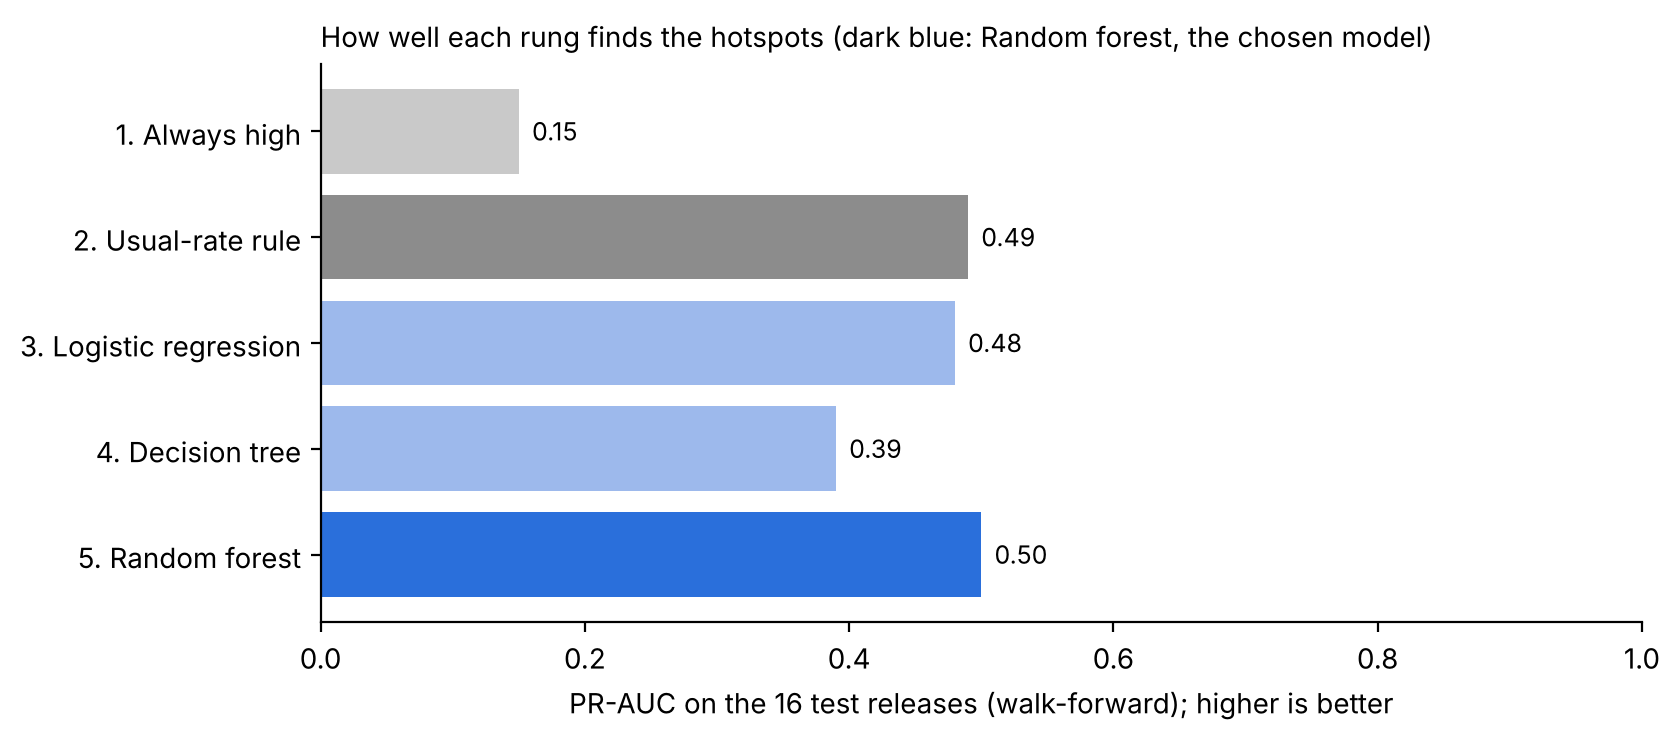

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
names = list(walk.index)
vals = walk['PR-AUC'].values
colors = ['#c9c9c9', '#8c8c8c'] + ['#2a6fdb' if FINAL in nm else '#9db9ec' for nm in names[2:]]
ax.barh(names[::-1], vals[::-1], color=colors[::-1])
for i, v in enumerate(vals[::-1]):
    ax.text(v + 0.01, i, f'{v:.2f}', va='center', fontsize=9)
ax.set_xlim(0, 1)
ax.set_xlabel('PR-AUC on the 16 test releases (walk-forward); higher is better')
ax.set_title(f'How well each rung finds the hotspots (dark blue: {FINAL}, the chosen model)', loc='left', fontsize=10)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
(ROOT / 'reports').mkdir(exist_ok=True)
plt.savefig(ROOT / 'reports' / 'model_ladder.png', dpi=150)
plt.show()

## 7. Per test release: the three components each approach would test first

How many of each approach's top three were real hotspots (walk-forward scores for the chosen model).

In [9]:
view = test[['release_key', 'window_start', 'component', 'high_risk']].copy()
view['model'] = wf_scores[FINAL]
view['rule'] = fixed_scores['Usual-rate rule']
short = lambda c: c.split(' (')[0].split(',')[0]
def top3(g, col):
    t = g.sort_values(col, ascending=False, kind='stable').head(3)
    return ', '.join(short(c) for c in t.component), int(t.high_risk.sum())
rows = []
for rel, g in view.sort_values('window_start').groupby('release_key', sort=False):
    m_list, m_hits = top3(g, 'model')
    r_list, r_hits = top3(g, 'rule')
    rows.append({'release': rel, 'real hotspots': int(g.high_risk.sum()), f'{FINAL} top 3': m_list,
                 'model hits': m_hits, 'rule top 3': r_list, 'rule hits': r_hits})
per_release = pd.DataFrame(rows)
per_release

,release,real hotspots,Random forest top 3,model hits,rule top 3,rule hits
0,Vendor E 8.2,0,"Vendor E, Self-checkout, Promotions",0,"Vendor E, Promotions, Receipts and printing",0
1,Vendor C 5.3,0,"Environment and infrastructure, Scan and go, Promotions",0,"Scan and go, Environment and infrastructure, Promotions",0
2,Vendor D v2.24,0,Vendor D,0,Vendor D,0
3,CI 11.1,2,"Self-checkout, Environment and infrastructure, Reporting",1,"Self-checkout, Environment and infrastructure, Payments and PED",1
4,Vendor D v2.25,0,Vendor D,0,Vendor D,0
5,1.51,0,"Environment and infrastructure, Reporting, Payments and PED",0,"Environment and infrastructure, Promotions, Payments and PED",0
6,CI 11.2,3,"Self-checkout, Environment and infrastructure, Receipts and printing",2,"Self-checkout, Environment and infrastructure, Payments and PED",1
7,CI 11.3,2,"Self-checkout, Environment and infrastructure, Receipts and printing",2,"Self-checkout, Environment and infrastructure, Payments and PED",2
8,1.52,3,"Environment and infrastructure, Reporting, Self-checkout",1,"Environment and infrastructure, Promotions, Self-checkout",1
9,CI 11.4,1,"Self-checkout, Environment and infrastructure, Receipts and printing",1,"Self-checkout, Environment and infrastructure, Payments and PED",1


In [10]:
print(f"Hotspots in the top 3 per release: {FINAL} {per_release['model hits'].sum()}, "
      f"usual-rate rule {per_release['rule hits'].sum()}, out of {per_release['real hotspots'].sum()} real hotspots")

Hotspots in the top 3 per release: Random forest 16, usual-rate rule 15, out of 24 real hotspots


## 8. What drives the risk?

**The decision tree's rules in plain words** (trained on all training releases). Each line is one path from the top question to a leaf, with how many training rows ended there and the share that were hotspots.

In [11]:
tree_pipe = fitted['Decision tree']
tree = tree_pipe.named_steps['model']
names = [n.replace('num__', '').replace('cat__', '') for n in tree_pipe.named_steps['prep'].get_feature_names_out()]
t = tree.tree_
Xt = tree_pipe.named_steps['prep'].transform(learn_rows[COLS])
leaf_of = tree.apply(Xt)
y_learn = learn_rows.high_risk.values

def paths(node=0, conds=()):
    if t.children_left[node] == -1:
        rows_here = leaf_of == node
        yield conds, int(rows_here.sum()), y_learn[rows_here].mean() if rows_here.any() else np.nan
        return
    f, thr = names[t.feature[node]], t.threshold[node]
    is_flag = set(np.unique(Xt[:, t.feature[node]].toarray() if hasattr(Xt, 'toarray') else Xt[:, t.feature[node]])) <= {0, 1}
    left = f'not {f}' if is_flag else f'{f} <= {thr:.2f}'
    right = f'{f}' if is_flag else f'{f} > {thr:.2f}'
    yield from paths(t.children_left[node], conds + (left,))
    yield from paths(t.children_right[node], conds + (right,))

rules = pd.DataFrame([{'path': ' AND '.join(c), 'training rows': n_rows, 'share hotspots': share}
                      for c, n_rows, share in paths()])
rules.sort_values('share hotspots', ascending=False).round(2)

,path,training rows,share hotspots
21,hist_sev_rate_per_10pd > 2.27 AND hist_reopened > 1.50 AND prev_density_per_10pd > 0.83 AND spread_share > 0.78,28,1.00
14,hist_sev_rate_per_10pd > 2.27 AND hist_reopened <= 1.50 AND gap_days <= 201.50 AND recent_rate_hl2 <= 0.74 AND hist_rate_per_10pd > 0.66,11,0.91
20,hist_sev_rate_per_10pd > 2.27 AND hist_reopened > 1.50 AND prev_density_per_10pd > 0.83 AND spread_share <= 0.78,5,0.80
11,hist_sev_rate_per_10pd <= 2.27 AND recent_90d > 1.50 AND prev_density_per_10pd > 0.18 AND n_prev_releases > 5.50 AND n_prev_releases <= 16.50,26,0.65
6,hist_sev_rate_per_10pd <= 2.27 AND recent_90d > 1.50 AND prev_density_per_10pd <= 0.18 AND hist_sev_rate_per_10pd <= 0.13 AND n_concurrent > 1.50,7,0.57
15,hist_sev_rate_per_10pd > 2.27 AND hist_reopened <= 1.50 AND gap_days <= 201.50 AND recent_rate_hl2 > 0.74 AND recent_90d <= 15.50,21,0.52
13,hist_sev_rate_per_10pd > 2.27 AND hist_reopened <= 1.50 AND gap_days <= 201.50 AND recent_rate_hl2 <= 0.74 AND hist_rate_per_10pd <= 0.66,5,0.40
18,hist_sev_rate_per_10pd > 2.27 AND hist_reopened <= 1.50 AND gap_days > 201.50 AND gap_days > 290.50,8,0.38
4,hist_sev_rate_per_10pd <= 2.27 AND recent_90d <= 1.50 AND hist_reopened > 1.50,6,0.33
9,hist_sev_rate_per_10pd <= 2.27 AND recent_90d > 1.50 AND prev_density_per_10pd > 0.18 AND n_prev_releases <= 5.50 AND n_prev_releases <= 1.50,28,0.29


**Logistic regression: the strongest weights** (inputs are on one scale, so the weights compare fairly; positive = more risk).

In [12]:
lr_pipe = fitted['Logistic regression']
lr_names = [n.replace('num__', '').replace('cat__', '') for n in lr_pipe.named_steps['prep'].get_feature_names_out()]
weights = pd.Series(lr_pipe.named_steps['model'].coef_[0], index=lr_names)
weights.sort_values(key=abs, ascending=False).head(12).round(2).to_frame('weight')

,weight
hist_sev_rate_per_10pd,0.30
hist_reopened,0.27
recent_90d,0.27
spread_share,0.25
hist_share,0.25
component_Environment and infrastructure,0.23
component_Self-checkout (SCO),0.20
vendor_Vendor A,0.16
spread_releases,0.15
n_prev_releases,-0.14


**The chosen model: how much the test PR-AUC drops when each input is shuffled** (a bigger drop means the model leans on that input more).

In [13]:
imp = permutation_importance(fitted[FINAL], test[COLS], test.high_risk, scoring='average_precision',
                             n_repeats=30, random_state=42)
pd.Series(imp.importances_mean, index=COLS).sort_values(ascending=False).round(3).to_frame('drop in PR-AUC')

,drop in PR-AUC
hist_sev_rate_per_10pd,0.064
recent_rate_hl2,0.063
hist_rate_per_10pd,0.060
hist_reopened,0.044
hist_share,0.037
prev_density_per_10pd,0.027
component,0.025
spread_share,0.025
n_prev_releases,0.019
recent_90d,0.011


## 9. Save

- `model_results`: training-check, fixed-test and walk-forward results for every rung.
- `model_scores`: component scores for step 6 (release rating). Each release with at least eight finished releases before it is scored by the chosen model trained only on releases that had finished before it started, so every score is a true "before the release" score.

In [14]:
make_final, scale_final, _ = MODELS[FINAL]
starts = fact.groupby('release_key').window_start.min().sort_values()
ends = fact.groupby('release_key').window_end.max()
replay = []
for rel, start in starts.items():
    finished = ends[ends < start].index
    known = rows_to_learn(fact[fact.release_key.isin(finished)], SETUPS[SETUP]['keep_estimated'])
    if len(finished) < 8 or known.high_risk.nunique() < 2:
        continue
    rows = fact[fact.release_key == rel]
    m = pipeline(NUM, make_final(CHOSEN_SETTING[FINAL]), scale_final).fit(known[COLS], known.high_risk)
    rule_s, _ = rule_scores(rows)
    replay.append(rows[['release_key', 'vendor', 'component', 'split', 'window_start', 'person_days', 'defects',
                        'density_per_10pd', 'high_risk']].assign(score=m.predict_proba(rows[COLS])[:, 1],
                                                                 usual_rate=rule_s))
scores = pd.concat(replay, ignore_index=True)

summary = pd.concat([cv.assign(view='training checks'),
                     fixed.reset_index(names='model').assign(view='fixed test'),
                     walk.reset_index(names='model').assign(view='walk-forward test')], ignore_index=True)
choice = pd.DataFrame([{'setup': SETUP, 'model': FINAL, 'setting': str(CHOSEN_SETTING[FINAL]),
                        'features': ','.join(NUM), 'keep_estimated': SETUPS[SETUP]['keep_estimated']}])
with sqlite3.connect(CLEAN) as cc:
    summary.to_sql('model_results', cc, if_exists='replace', index=False)
    scores.to_sql('model_scores', cc, if_exists='replace', index=False)
    choice.to_sql('model_choice', cc, if_exists='replace', index=False)   # so later notebooks rebuild the same model
print('chosen setup:', SETUP, '| chosen model:', FINAL, CHOSEN_SETTING[FINAL])
print('saved model_results', summary.shape, '| model_scores', scores.shape, 'for', scores.release_key.nunique(), 'releases')

chosen setup: half-life 2, with 1.37 and Vendor C 3.0 | chosen model: Random forest (None, 3)
saved model_results (98, 12) | model_scores (432, 11) for 41 releases


## What is next

Step 6: the release rating. The component scores of each release are rolled up into one rating per release (max, weighted average or threshold rule), and the three rules are compared against what really happened.